# 4. Feature evaluation

| | |
| --- | --- |
| **Purpose** | Find out which candidate features carry information about which labels, before any model is trained |
| **Input** | `data/hyperliquid/case_study_data/pre_holdout.parquet` from notebook 3. The holdout is **not** loaded |
| **Output** | Tables and charts only (nothing is saved) |
| **Functions** | `src/wh_research/evaluation/ic.py` (IC, HAC test, quantiles) and `plots.py` (charts) |
| **Workflow** | Step 7 of `docs/9-research_workflow.md` |

**Why evaluate on the pre-holdout data and not on folds.** A raw feature (a past return) has nothing fitted, so there is no train and evaluation part for it. We measure its relation to the labels on **all** pre-holdout data, and check that the relation is **stable over time** by repeating it on three separate time blocks. The walk-forward folds (train a model on the past, score it on the future) come later, after the features and the label are chosen, because the purge of the folds depends on the label horizon.

**What is measured.** For each pair of a feature and a label:
1. the **information coefficient (IC)**: how well, on each day, the ranking of the coins by the feature matches the ranking by the label
2. the **mean target per feature quintile**: whether the coins with the highest feature value really end up with a higher label than the coins with the lowest

In [36]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from wh_research.evaluation.ic import ic_by_block, ic_summary, quantile_table, quantile_table_by_block
from wh_research.evaluation.plots import plot_mean_ic_by_block, plot_quantile_means
from wh_research.evaluation.splits import find_fold_starts, find_holdout_start

# Load data

Only the pre-holdout set. All rows are in the universe, with the labels and features from notebook 3.

In [37]:
PROJECT_ROOT = Path.cwd().parent.parent
data_path = PROJECT_ROOT/"data/hyperliquid/case_study_data/pre_holdout.parquet"
df = pd.read_parquet(data_path)

### Settings

- `features`: the candidate features from notebook 3
- `labels`: the labels to compare with, as `{column: days ahead}`. The number of days is needed for the purge and for the standard error (see below). Only the return labels are used: a rank correlation with a 0/1 direction label carries less information and mostly repeats the return label
- `MIN_SYMBOLS`: a day needs at least this many coins to get an IC. Early 2023 has only 4 to 14 coins a day, and a rank correlation over a handful of coins is mostly noise. The count uses the coins that have the **feature**, not the label, because a coin's label depends on the future (a delisting removes it)
- `N_QUANTILES`: 5 quintiles

In [38]:
features = ["past_log_return_7", "past_log_return_14", "past_log_return_30"]
labels = {"fwd_log_return_1": 1, "fwd_log_return_3": 3, "fwd_log_return_7": 7}

MIN_SYMBOLS = 10
N_QUANTILES = 5

# Compute cross-sectional IC

On each day we rank the coins by the feature and by the forward return, and take the correlation of the two ranks (**Spearman**). That number is the day's cross-sectional information coefficient (IC). A positive IC means coins with a higher feature value tended to have a higher forward return that day; a negative IC means the opposite. Ranking makes it robust to outliers, and doing it **per day** removes market-wide moves: only the differences between coins on the same day matter.

We then test whether the **mean** daily IC is different from 0:

- **HAC / Newey-West standard error.** The 3 and 7-day forward returns overlap from one day to the next, so consecutive daily ICs are correlated and a plain t-test would overstate the significance. HAC (heteroskedasticity and autocorrelation consistent, also called Newey-West) corrects the standard error, with as many lags as the label has days.
- **t-stat and p-value** (two-sided, from the t distribution).
- **95% confidence interval** of the mean IC = mean IC ± the t critical value × the same HAC standard error, so it agrees with the p-value: it excludes 0 exactly when the p-value is below 0.05.

Columns: `days` (days used), `mean_ic`, `std_ic` (spread of the daily IC), `se_hac`, `ci_low`, `ci_high`, `t_stat_hac`, `p_value`.

In [39]:
# ic_daily has one column per feature-label pair with the IC of every day (handy for your own plots and slices)
ic_table, ic_daily = ic_summary(df, features, labels, min_symbols=MIN_SYMBOLS)

ic_table.round(4)

days  mean_ic  std_ic  se_hac  ci_low  \
feature            label                                                     
past_log_return_7  fwd_log_return_1   744  -0.0274  0.2463  0.0088 -0.0447   
                   fwd_log_return_3   744  -0.0225  0.2558  0.0132 -0.0484   
                   fwd_log_return_7   744  -0.0174  0.2549  0.0183 -0.0533   
past_log_return_14 fwd_log_return_1   744  -0.0019  0.2572  0.0089 -0.0195   
                   fwd_log_return_3   744   0.0088  0.2512  0.0130 -0.0168   
                   fwd_log_return_7   744   0.0319  0.2641  0.0194 -0.0061   
past_log_return_30 fwd_log_return_1   744   0.0056  0.2618  0.0093 -0.0127   
                   fwd_log_return_3   744   0.0270  0.2435  0.0127  0.0020   
                   fwd_log_return_7   744   0.0517  0.2440  0.0177  0.0169   

                                     ci_high  t_stat_hac  p_value  
feature            label                                           
past_log_return_7  fwd_log_return_1  -0.0100     -3.1004   0.0020  
                   fwd_log_return_3   0.0034     -1.7037   0.0889  
                   fwd_log_return_7   0.0185     -0.9527   0.3410  
past_log_return_14 fwd_log_return_1   0.0156     -0.2179   0.8275  
                   fwd_log_return_3   0.0344      0.6716   0.5020  
                   fwd_log_return_7   0.0700      1.6487   0.0996  
past_log_return_30 fwd_log_return_1   0.0238      0.5984   0.5498  
                   fwd_log_return_3   0.0520      2.1215   0.0342  
                   fwd_log_return_7   0.0865      2.9158   0.0037

# Mean target per feature quintile

The IC is one number per pair. To see the **shape** of the relationship we also look at the mean target in each feature quintile.

- On each day we rank the coins by the feature and cut them into 5 equal buckets: quintile 1 holds the coins with the lowest feature values and quintile 5 the highest
- On each day we take the mean target of every bucket, then average those daily means over all days. Cutting per day matches the cross-sectional IC and removes market-wide moves
- The buckets use every coin that has the feature on that day, so a coin's missing label cannot move the cut
- Days with fewer than 10 coins are skipped, as for the IC, so every bucket has at least 2 coins

A steady rise or fall from quintile 1 to 5 goes with a positive or negative IC. A jump in only one end bucket means the effect sits in one tail. All values are in percent.

**Mean vs median.** A mean can be moved by a single extreme coin (there are a handful of days with a coin moving more than 100%, such as a delisting or a manipulated listing). The **median** of each bucket ignores them. If the two disagree, the mean is being driven by outliers.

In [40]:
quantile_means = quantile_table(df, features, list(labels), statistic="mean", n_quantiles=N_QUANTILES, min_symbols=MIN_SYMBOLS)

quantile_means.round(3)

1      2      3      4      5
feature            label                                              
past_log_return_7  fwd_log_return_1 -0.138 -0.128 -0.092 -0.143 -0.009
                   fwd_log_return_3 -0.460 -0.230 -0.233 -0.398 -0.159
                   fwd_log_return_7 -1.091 -0.512 -0.559 -0.705 -0.785
past_log_return_14 fwd_log_return_1 -0.228 -0.154 -0.098 -0.077  0.064
                   fwd_log_return_3 -0.575 -0.508 -0.229 -0.167  0.013
                   fwd_log_return_7 -1.588 -0.910 -0.663 -0.246 -0.216
past_log_return_30 fwd_log_return_1 -0.297 -0.072 -0.102 -0.028  0.002
                   fwd_log_return_3 -0.786 -0.281 -0.214 -0.146 -0.031
                   fwd_log_return_7 -1.769 -0.500 -0.564 -0.612 -0.175

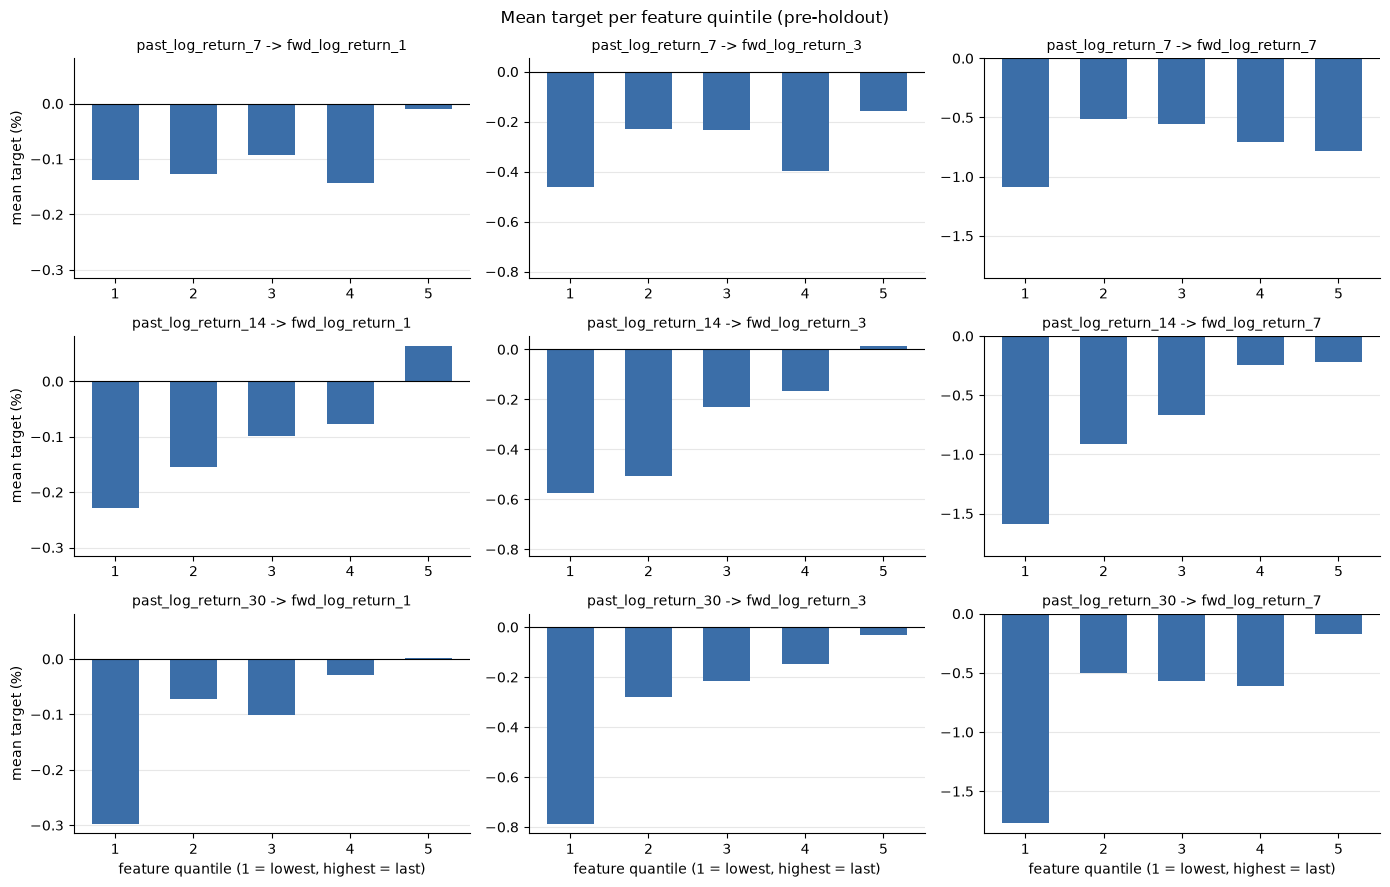

In [41]:
plot_quantile_means(quantile_means, "Mean target per feature quintile (pre-holdout)")
plt.show()

#### Median target per feature quintile

In [42]:
quantile_medians = quantile_table(df, features, list(labels), statistic="median", n_quantiles=N_QUANTILES, min_symbols=MIN_SYMBOLS)

quantile_medians.round(3)

1      2      3      4      5
feature            label                                              
past_log_return_7  fwd_log_return_1 -0.406 -0.354 -0.360 -0.476 -0.566
                   fwd_log_return_3 -0.861 -0.570 -0.639 -0.957 -0.915
                   fwd_log_return_7 -1.913 -1.209 -1.248 -1.630 -1.598
past_log_return_14 fwd_log_return_1 -0.466 -0.375 -0.346 -0.383 -0.417
                   fwd_log_return_3 -0.985 -0.865 -0.706 -0.674 -0.739
                   fwd_log_return_7 -2.269 -1.697 -1.469 -1.153 -1.154
past_log_return_30 fwd_log_return_1 -0.546 -0.308 -0.362 -0.396 -0.435
                   fwd_log_return_3 -1.193 -0.681 -0.713 -0.729 -0.741
                   fwd_log_return_7 -2.434 -1.334 -1.376 -1.339 -1.184

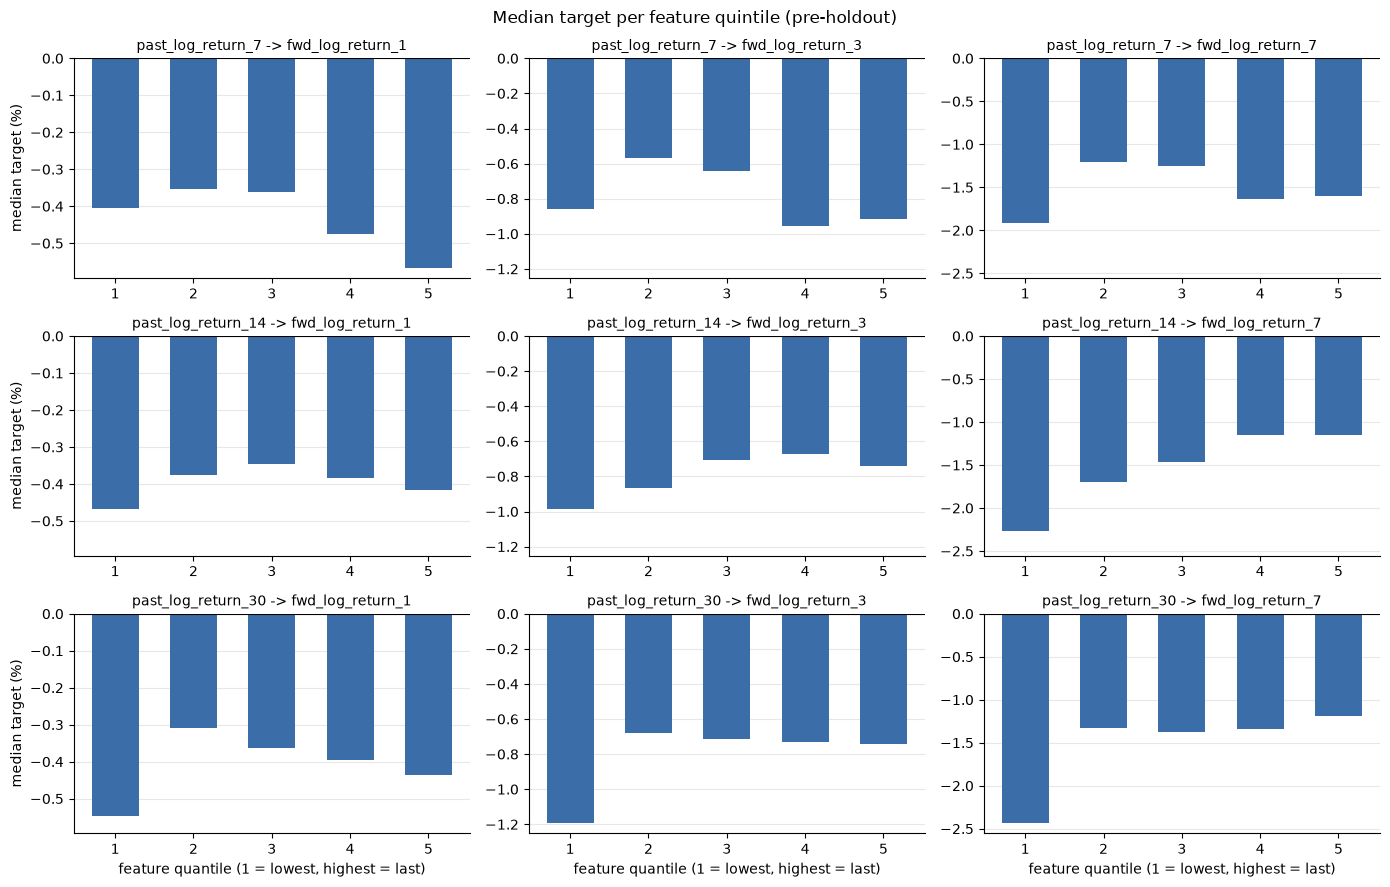

In [43]:
plot_quantile_means(quantile_medians, "Median target per feature quintile (pre-holdout)", ylabel="median target (%)")
plt.show()

# IC and quintiles by block

A feature is only useful if its IC holds up over time, so we repeat the same calculations on separate periods of the pre-holdout data. Nothing is fitted for a raw feature, so the periods are used as plain time blocks, cut at the dates decided in `2_determining_cv_folds`:

- block 1: from the start to the fold 1 evaluation start (fold 1's train period)
- block 2: the fold 1 evaluation period
- block 3: the fold 2 evaluation period

The blocks do not overlap, so no day is counted twice (the fold 2 train set is block 1 plus block 2, so it is not a block of its own). Block 1 is thin: early 2023 has few coins a day, and days with fewer than 10 coins are skipped.

A row stays in a block only if its label ends before the block ends (`fwd_end_time_{n}`, with the horizon of the label being tested), so no label looks into the next block and the blocks stay independent. The holdout is not touched.

**The boundary dates are recomputed** with `find_holdout_start` and `find_fold_starts`, the same functions as in notebook 2. We load only two columns of the frozen universe file for this (`open_time` and `in_universe`), because the pre-holdout file is missing its last 7 days and would give slightly different dates. No prices or labels of the holdout are read.

In [44]:
universe_path = PROJECT_ROOT/"data/hyperliquid/case_study_data/universe_1d_min_mdv_2m_exit_1m_280323_171026.parquet"
universe_days = pd.read_parquet(universe_path, columns=["open_time", "in_universe"])

holdout_start = find_holdout_start(universe_days)
fold1_eval_start, fold2_eval_start = find_fold_starts(universe_days, holdout_start)

# each block runs from its start (included) to its end (not included)
blocks = {
    "block 1": (df["open_time"].min(), fold1_eval_start),
    "block 2": (fold1_eval_start, fold2_eval_start),
    "block 3": (fold2_eval_start, holdout_start),
}

# the pre-holdout data must end before the holdout starts
assert df["open_time"].max() < holdout_start

for name, (start, end) in blocks.items():
    block = df[(df["open_time"] >= start) & (df["open_time"] < end)]
    print(f"{name}: {start.date()} to {end.date()}, {block['open_time'].nunique()} days, {len(block)} rows")

block 1: 2023-03-28 to 2024-03-25, 363 days, 6531 rows
block 2: 2024-03-25 to 2024-12-23, 273 days, 13507 rows
block 3: 2024-12-23 to 2025-09-22, 266 days, 17687 rows


### IC by block

The three blocks of a pair sit next to each other. `days` is the number of days used in the block (days with too few coins and the purged last days are not counted).

In [45]:
block_table = ic_by_block(df, blocks, features, labels, min_symbols=MIN_SYMBOLS)

block_table.round(4)

days  mean_ic  std_ic  se_hac  \
feature            label            block                                    
past_log_return_7  fwd_log_return_1 block 1   204  -0.0355  0.2894  0.0194   
                   fwd_log_return_3 block 1   202  -0.0311  0.3091  0.0309   
                   fwd_log_return_7 block 1   198  -0.0490  0.2996  0.0403   
past_log_return_14 fwd_log_return_1 block 1   204  -0.0151  0.3016  0.0191   
                   fwd_log_return_3 block 1   202   0.0002  0.2981  0.0304   
                   fwd_log_return_7 block 1   198   0.0221  0.3150  0.0429   
past_log_return_30 fwd_log_return_1 block 1   204  -0.0158  0.3034  0.0204   
                   fwd_log_return_3 block 1   202   0.0086  0.2756  0.0268   
                   fwd_log_return_7 block 1   198   0.0226  0.2521  0.0314   
past_log_return_7  fwd_log_return_1 block 2   272  -0.0270  0.2295  0.0135   
                   fwd_log_return_3 block 2   270  -0.0276  0.2388  0.0213   
                   fwd_log_return_7 block 2   266  -0.0390  0.2443  0.0308   
past_log_return_14 fwd_log_return_1 block 2   272  -0.0179  0.2362  0.0136   
                   fwd_log_return_3 block 2   270  -0.0201  0.2224  0.0194   
                   fwd_log_return_7 block 2   266  -0.0207  0.2362  0.0279   
past_log_return_30 fwd_log_return_1 block 2   272  -0.0009  0.2382  0.0140   
                   fwd_log_return_3 block 2   270   0.0080  0.2324  0.0210   
                   fwd_log_return_7 block 2   266   0.0277  0.2426  0.0300   
past_log_return_7  fwd_log_return_1 block 3   266  -0.0207  0.2278  0.0139   
                   fwd_log_return_3 block 3   266  -0.0075  0.2264  0.0183   
                   fwd_log_return_7 block 3   266   0.0289  0.2247  0.0255   
past_log_return_14 fwd_log_return_1 block 3   266   0.0258  0.2393  0.0142   
                   fwd_log_return_3 block 3   266   0.0469  0.2366  0.0193   
                   fwd_log_return_7 block 3   266   0.0925  0.2401  0.0299   
past_log_return_30 fwd_log_return_1 block 3   266   0.0287  0.2503  0.0148   
                   fwd_log_return_3 block 3   266   0.0594  0.2265  0.0191   
                   fwd_log_return_7 block 3   266   0.0928  0.2358  0.0295   

                                             ci_low  ci_high  t_stat_hac  \
feature            label            block                                  
past_log_return_7  fwd_log_return_1 block 1 -0.0738   0.0027     -1.8311   
                   fwd_log_return_3 block 1 -0.0920   0.0298     -1.0077   
                   fwd_log_return_7 block 1 -0.1284   0.0304     -1.2161   
past_log_return_14 fwd_log_return_1 block 1 -0.0527   0.0226     -0.7897   
                   fwd_log_return_3 block 1 -0.0598   0.0601      0.0052   
                   fwd_log_return_7 block 1 -0.0626   0.1067      0.5138   
past_log_return_30 fwd_log_return_1 block 1 -0.0561   0.0245     -0.7717   
                   fwd_log_return_3 block 1 -0.0442   0.0614      0.3217   
                   fwd_log_return_7 block 1 -0.0394   0.0846      0.7201   
past_log_return_7  fwd_log_return_1 block 2 -0.0537  -0.0004     -1.9955   
                   fwd_log_return_3 block 2 -0.0697   0.0144     -1.2954   
                   fwd_log_return_7 block 2 -0.0996   0.0216     -1.2683   
past_log_return_14 fwd_log_return_1 block 2 -0.0447   0.0090     -1.3113   
                   fwd_log_return_3 block 2 -0.0583   0.0180     -1.0387   
                   fwd_log_return_7 block 2 -0.0755   0.0342     -0.7417   
past_log_return_30 fwd_log_return_1 block 2 -0.0283   0.0266     -0.0626   
                   fwd_log_return_3 block 2 -0.0334   0.0495      0.3827   
                   fwd_log_return_7 block 2 -0.0314   0.0868      0.9227   
past_log_return_7  fwd_log_return_1 block 3 -0.0481   0.0067     -1.4848   
                   fwd_log_return_3 block 3 -0.0435   0.0285     -0.4112   
                   fwd_log_return_7 block 3 -0.0214   0.0792      1.1311   
past_log_return_14 fwd_log_return_

### Mean IC by block

One bar per block, with the 95% confidence interval as the line on each bar. A bar whose interval crosses 0, or a bar that flips sign between blocks, means the IC is not stable.

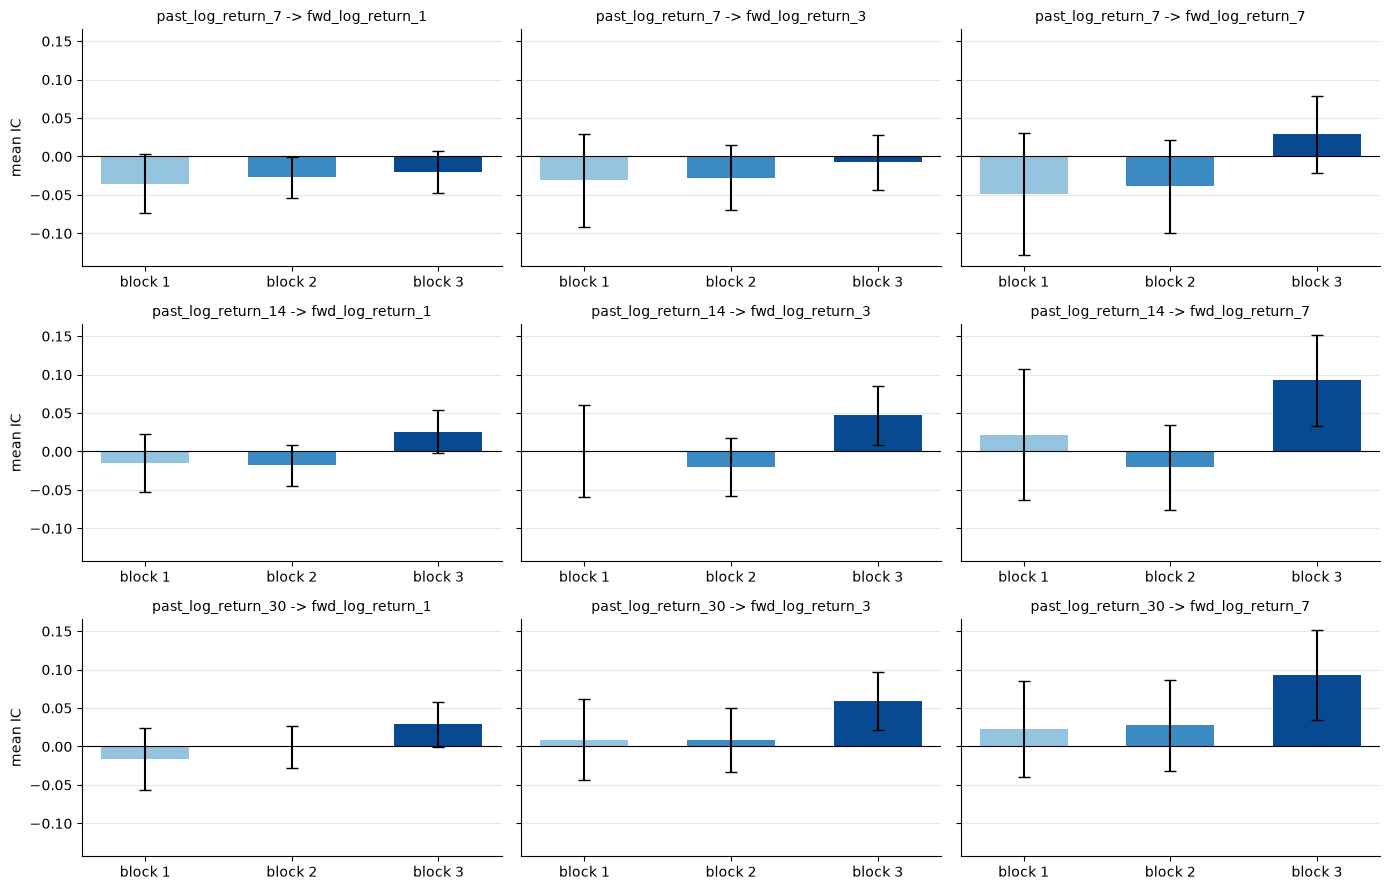

In [46]:
plot_mean_ic_by_block(block_table)
plt.show()

### Mean target per feature quintile by block

The same quintile calculation as above, run inside each block (rows purged for the label's horizon). Compare quintiles **within** a block: the overall level of the target changes with the market, for example the targets are positive on average in block 1 and negative in blocks 2 and 3.

In [47]:
block_quantile_means = quantile_table_by_block(df, blocks, features, labels, statistic="mean", n_quantiles=N_QUANTILES, min_symbols=MIN_SYMBOLS)

block_quantile_means.round(3)

1      2      3      4      5
block   feature            label                                              
block 1 past_log_return_7  fwd_log_return_1  0.123  0.134  0.160  0.123  0.536
                           fwd_log_return_3  0.256  0.542  0.501  0.505  1.173
                           fwd_log_return_7  0.799  1.285  0.826  1.078  1.702
        past_log_return_14 fwd_log_return_1  0.071  0.137  0.216  0.245  0.461
                           fwd_log_return_3  0.211  0.217  0.717  0.738  1.131
                           fwd_log_return_7  0.033  0.837  1.171  1.902  1.868
        past_log_return_30 fwd_log_return_1  0.067  0.197  0.174  0.429  0.255
                           fwd_log_return_3  0.210  0.613  0.602  0.944  0.685
                           fwd_log_return_7  0.812  1.263  1.136  1.054  1.538
block 2 past_log_return_7  fwd_log_return_1 -0.139 -0.265 -0.165 -0.161 -0.162
                           fwd_log_return_3 -0.438 -0.609 -0.388 -0.598 -0.547
                           fwd_log_return_7 -0.690 -1.209 -0.793 -1.087 -1.465
        past_log_return_14 fwd_log_return_1 -0.143 -0.216 -0.183 -0.183 -0.167
                           fwd_log_return_3 -0.374 -0.522 -0.552 -0.571 -0.563
                           fwd_log_return_7 -0.735 -0.985 -1.212 -1.114 -1.198
        past_log_return_30 fwd_log_return_1 -0.236 -0.187 -0.109 -0.301 -0.067
                           fwd_log_return_3 -0.557 -0.663 -0.443 -0.654 -0.295
                           fwd_log_return_7 -1.217 -1.164 -0.896 -1.340 -0.642
block 3 past_log_return_7  fwd_log_return_1 -0.379 -0.230 -0.253 -0.363 -0.306
                           fwd_log_return_3 -1.188 -0.574 -0.774 -1.007 -0.902
                           fwd_log_return_7 -3.026 -1.256 -1.435 -1.739 -2.012
        past_log_return_14 fwd_log_return_1 -0.584 -0.362 -0.292 -0.245 -0.040
                           fwd_log_return_3 -1.535 -1.186 -0.758 -0.601 -0.354
                           fwd_log_return_7 -3.736 -2.225 -1.587 -1.100 -0.831
        past_log_return_30 fwd_log_return_1 -0.681 -0.200 -0.343 -0.134 -0.161
                           fwd_log_return_3 -1.930 -0.707 -0.731 -0.573 -0.476
                           fwd_log_return_7 -4.294 -1.198 -1.578 -1.197 -1.183

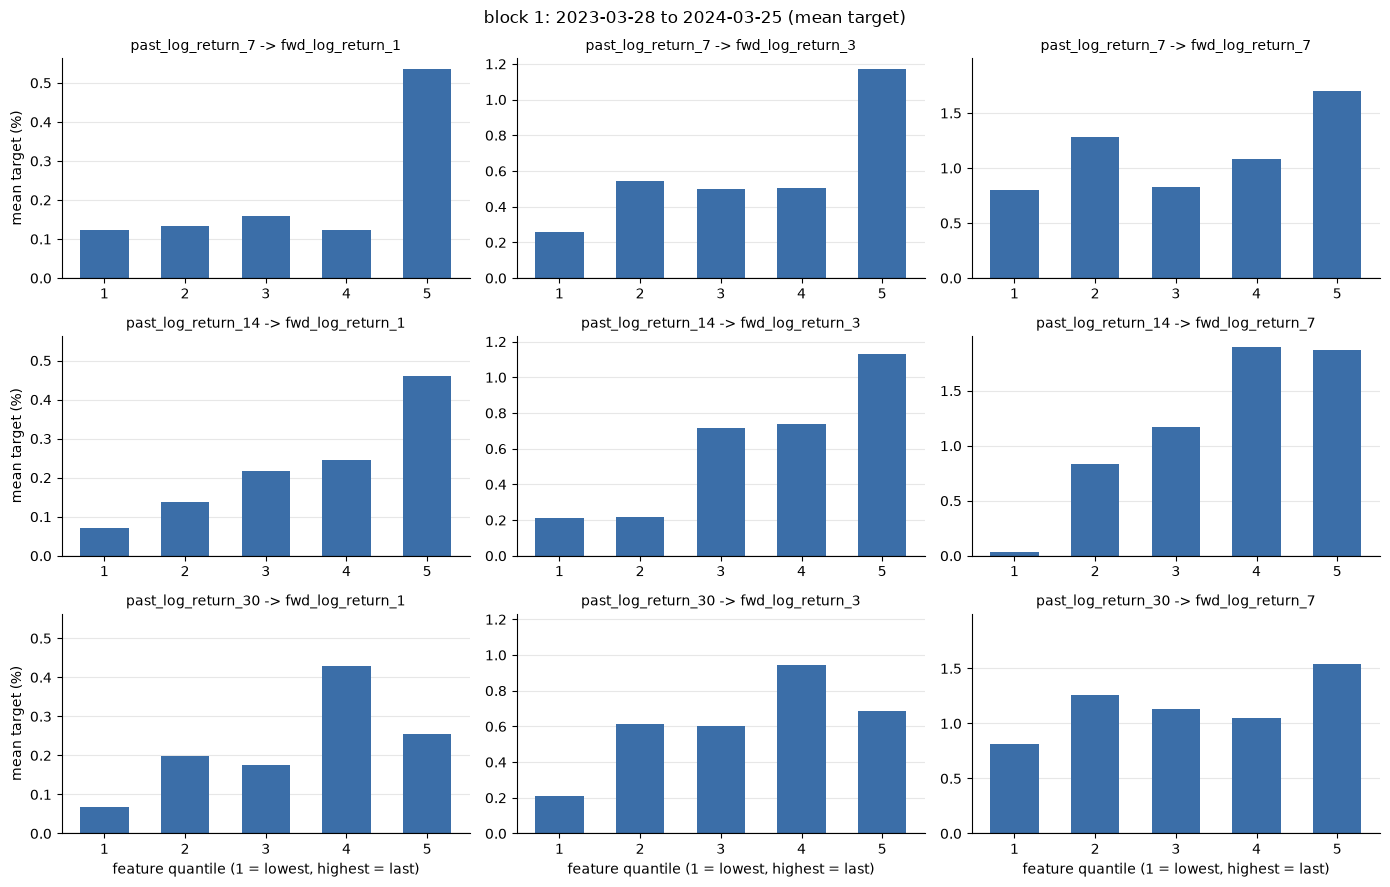

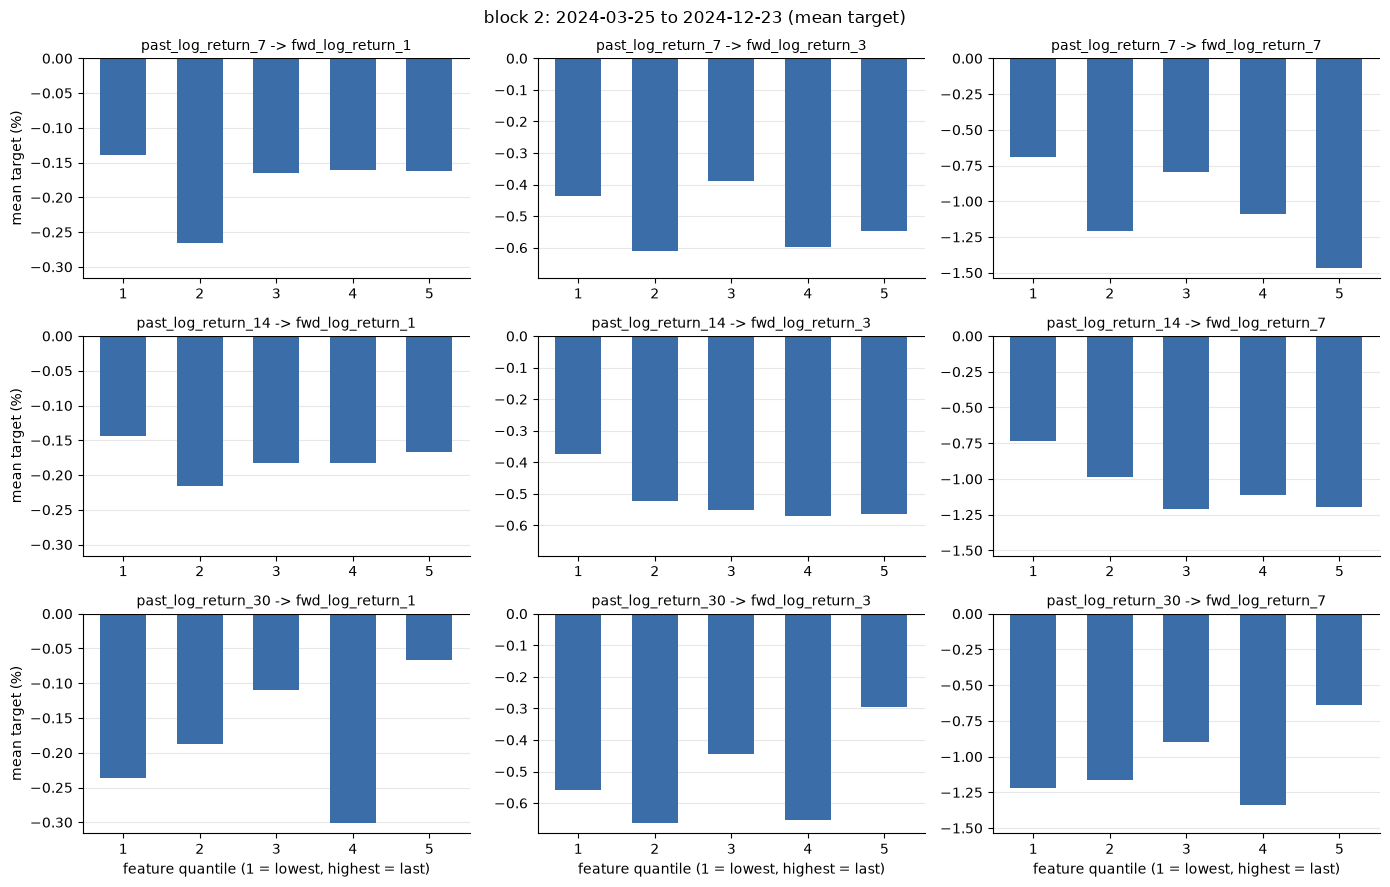

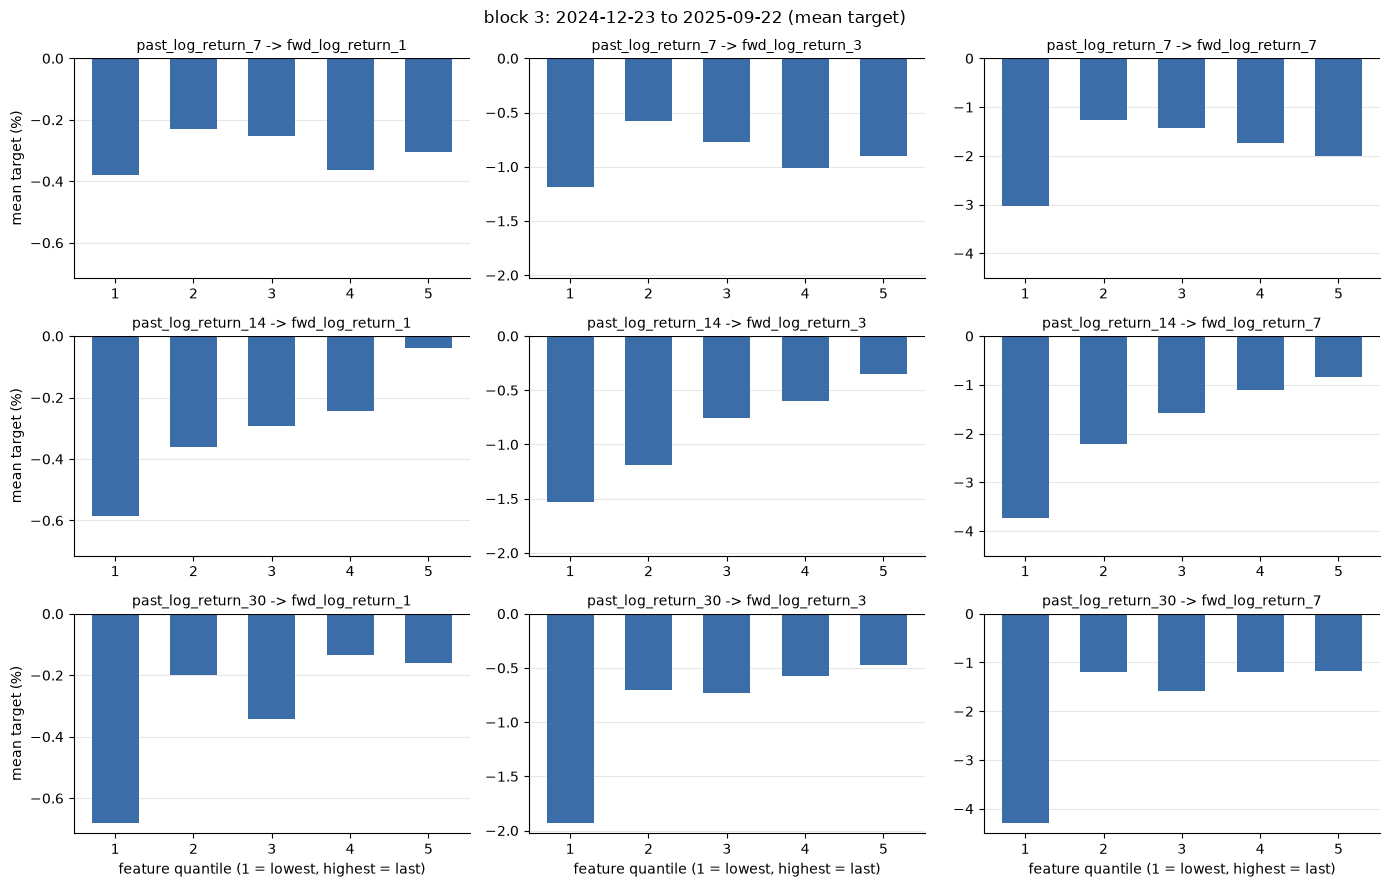

In [48]:
for block, (start, end) in blocks.items():
    plot_quantile_means(block_quantile_means.loc[block], f"{block}: {start.date()} to {end.date()} (mean target)")
    plt.show()

#### Median target per feature quintile by block

In [49]:
block_quantile_medians = quantile_table_by_block(df, blocks, features, labels, statistic="median", n_quantiles=N_QUANTILES, min_symbols=MIN_SYMBOLS)

block_quantile_medians.round(3)

1      2      3      4      5
block   feature            label                                              
block 1 past_log_return_7  fwd_log_return_1 -0.201 -0.265 -0.119 -0.296 -0.110
                           fwd_log_return_3 -0.267  0.063 -0.048 -0.288  0.023
                           fwd_log_return_7 -0.379  0.442 -0.034 -0.380  0.125
        past_log_return_14 fwd_log_return_1 -0.200 -0.128 -0.162 -0.149 -0.095
                           fwd_log_return_3 -0.322 -0.253 -0.057  0.005  0.047
                           fwd_log_return_7 -0.731 -0.168 -0.385  0.528  0.158
        past_log_return_30 fwd_log_return_1 -0.185 -0.034 -0.155 -0.134 -0.283
                           fwd_log_return_3 -0.416  0.218 -0.040  0.017 -0.205
                           fwd_log_return_7 -0.650  0.397 -0.054 -0.137  0.532
block 2 past_log_return_7  fwd_log_return_1 -0.472 -0.530 -0.463 -0.571 -0.795
                           fwd_log_return_3 -0.959 -0.974 -0.962 -1.361 -1.323
                           fwd_log_return_7 -1.891 -1.788 -1.620 -1.967 -2.379
        past_log_return_14 fwd_log_return_1 -0.500 -0.515 -0.474 -0.547 -0.703
                           fwd_log_return_3 -0.971 -1.106 -1.101 -1.157 -1.231
                           fwd_log_return_7 -1.818 -1.940 -1.951 -2.017 -2.027
        past_log_return_30 fwd_log_return_1 -0.580 -0.488 -0.480 -0.616 -0.559
                           fwd_log_return_3 -1.148 -1.197 -1.000 -1.227 -1.197
                           fwd_log_return_7 -2.052 -1.997 -1.729 -2.057 -2.010
block 3 past_log_return_7  fwd_log_return_1 -0.535 -0.288 -0.482 -0.553 -0.715
                           fwd_log_return_3 -1.370 -0.778 -0.907 -1.198 -1.332
                           fwd_log_return_7 -3.159 -1.937 -1.854 -2.290 -2.185
        past_log_return_14 fwd_log_return_1 -0.677 -0.467 -0.396 -0.425 -0.410
                           fwd_log_return_3 -1.650 -1.231 -0.940 -0.853 -0.943
                           fwd_log_return_7 -3.957 -2.686 -1.836 -1.645 -1.331
        past_log_return_30 fwd_log_return_1 -0.826 -0.377 -0.439 -0.411 -0.470
                           fwd_log_return_3 -1.972 -0.987 -1.062 -0.917 -0.865
                           fwd_log_return_7 -4.211 -1.999 -2.090 -1.577 -1.853

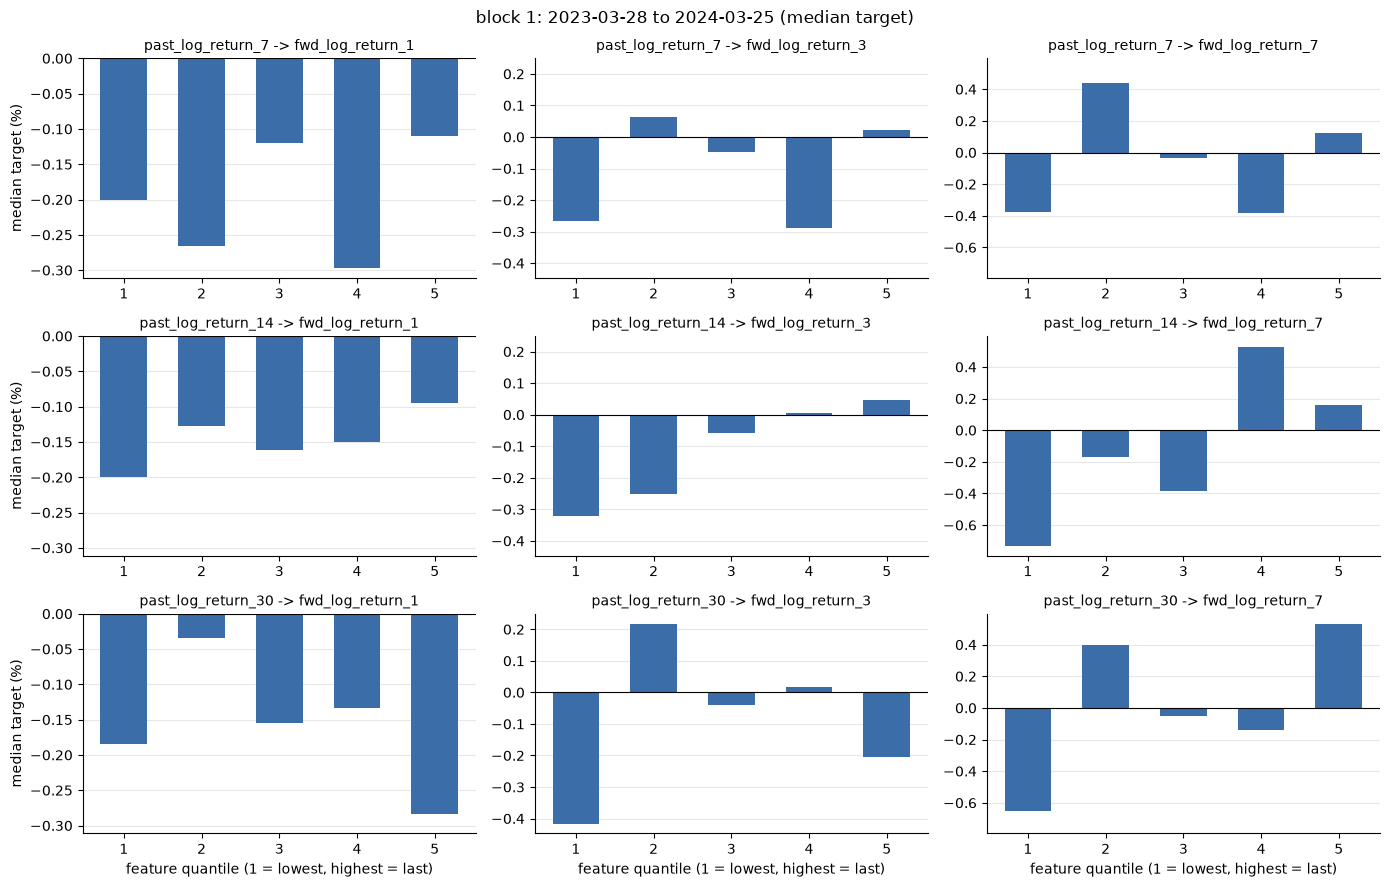

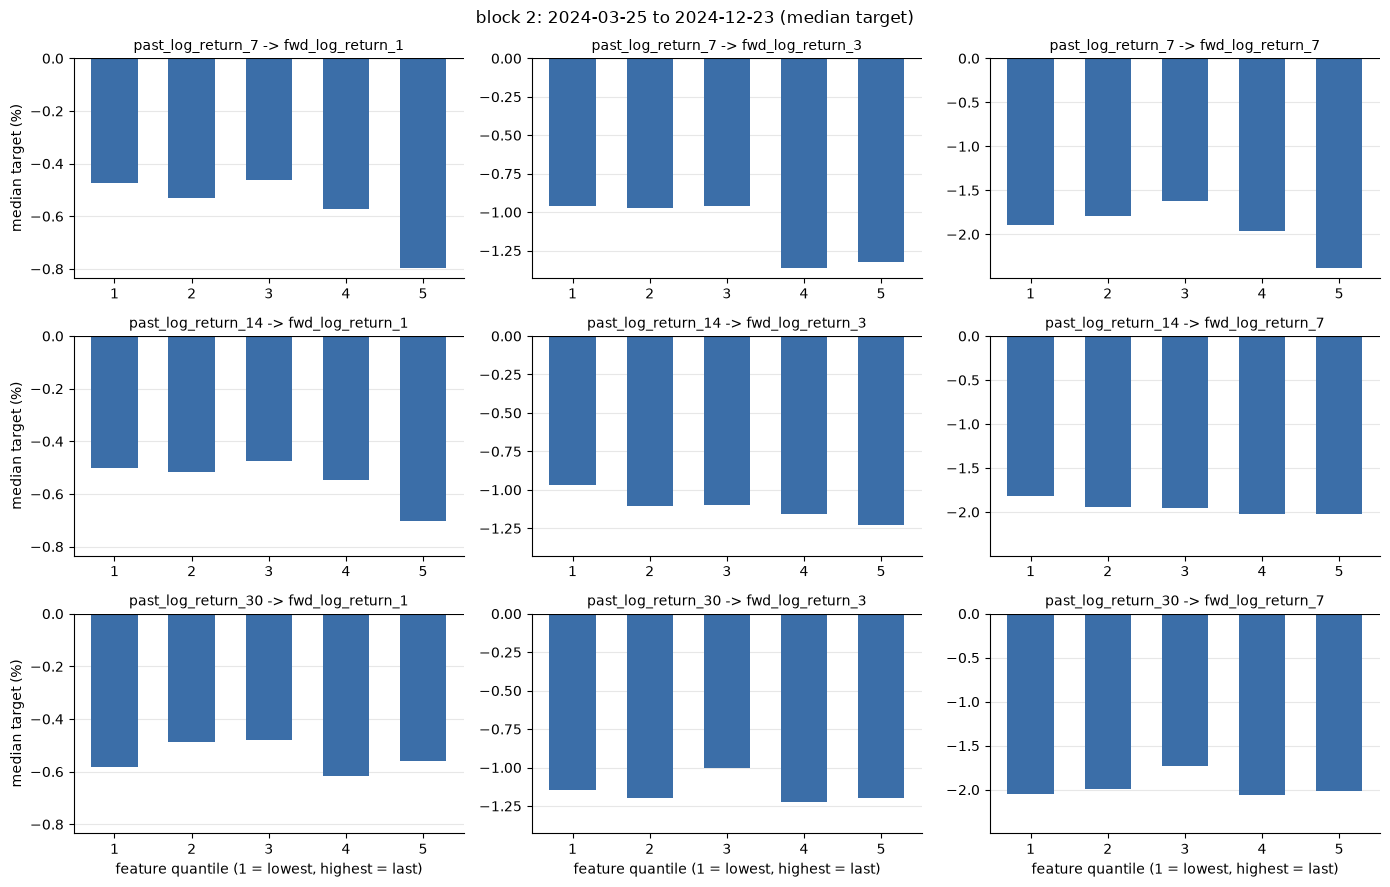

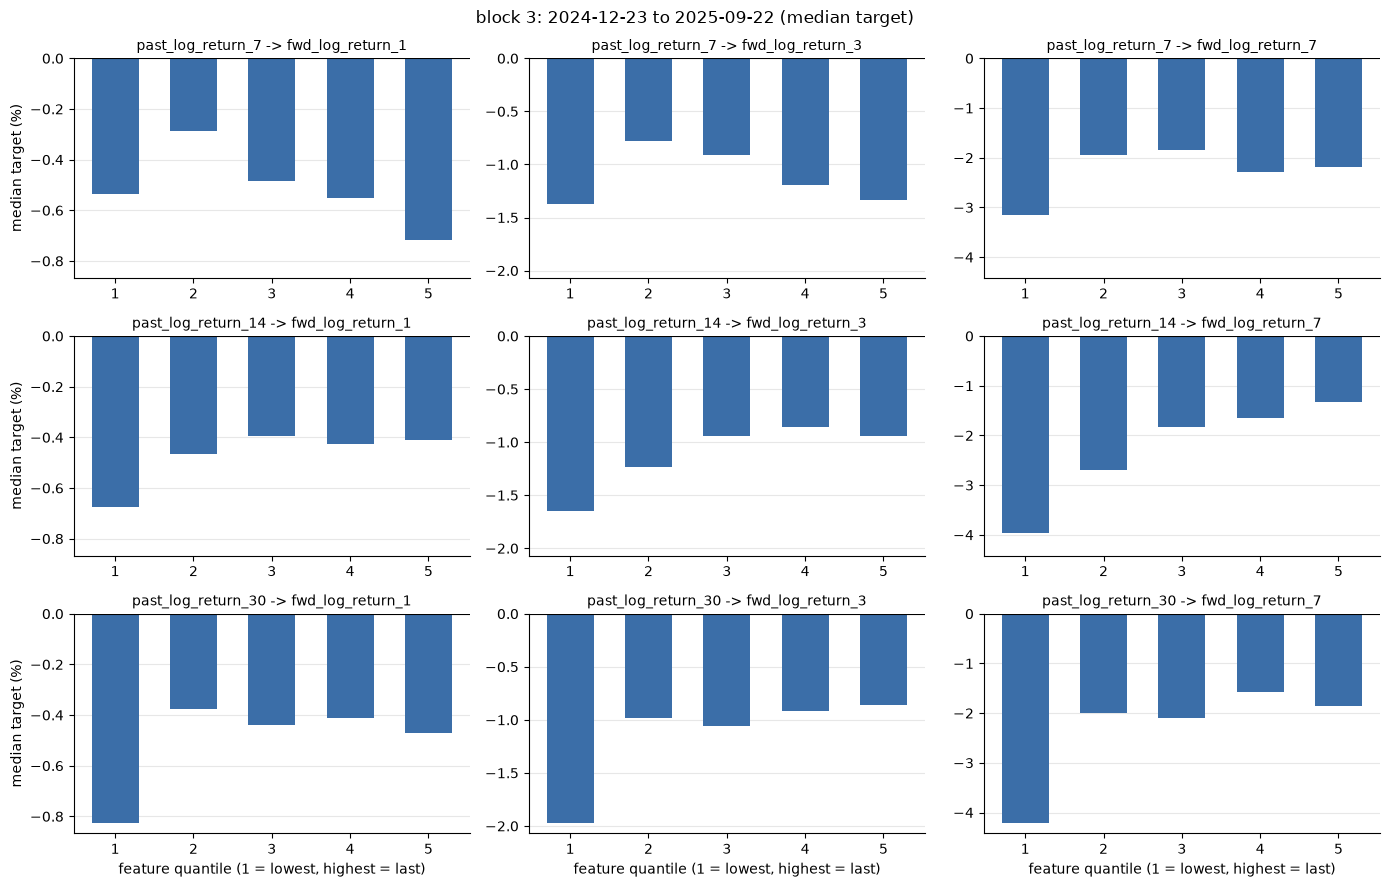

In [50]:
for block, (start, end) in blocks.items():
    plot_quantile_means(block_quantile_medians.loc[block], f"{block}: {start.date()} to {end.date()} (median target)", ylabel="median target (%)")
    plt.show()

# Limitations and known biases

None of these is look-ahead (that was audited, see `docs/10-case_study_1_audit.md`). They are the ways in which the numbers above can still mislead, and they are worth keeping in mind when you write the conclusion:

- **Many tests, unadjusted p-values.** The IC table has 9 tests, the block table 27. A single p-value below 0.05 among many tests is weak evidence. The audit applied Holm and Benjamini-Hochberg corrections to these tests and found that far fewer results survive than the raw table suggests.
- **One period can drive a result.** Compare the blocks: a whole-period IC that is significant in only one block is a statement about that period.
- **Block 1 is thin.** Early on there are few coins, so each daily IC is noisy and the block-1 intervals are wide.
- **Means are sensitive to outliers.** Use the median tables next to the mean tables. The IC itself is rank based and robust.
- **Missing labels are dropped.** Coins that stop trading while in the universe lose their last labels. Few rows here, but the final evaluation on the holdout is more exposed and must treat delistings explicitly.
- **Price returns only.** Labels are close-to-close log-returns. They include no trading costs or slippage, no funding payments (perpetual futures pay or receive funding every hour, and the features are mildly correlated with funding), and assume you can trade at the same close the feature is computed from.
- **Equal weight down to $2M of daily volume.** The IC treats every coin alike, including the least liquid ones, which limits how much capital can follow a signal.
- **The holdout has been partly seen.** An earlier version of notebook 3 printed label base rates over all rows including the holdout. This is disclosed in the audit document. Treat the final evaluation accordingly: nothing may be tuned on the holdout.

# Conclusion